# A neural network for the energy use of Seattle buildings
Day 4 assignment, neural networks, Track A1 (an MLP on tables)

Chloe Hraibeh, Jeff El Khoury, Luca Obejdeanu
AI Methods I, IAAC MaAI 2026/27

### Use case
Same question as our Day 2 model: an architect doing a feasibility study for a new building in Seattle wants a first idea of its yearly energy use per m2, before anything is designed in detail. They only know the use, the size, the number of floors, the year and the location. Here we try a neural network on the same problem and check if it does better than our Day 2 random forest.

### The three questions
1. **Who uses it, and for what?** The architect, for a first estimate in a feasibility study.
2. **What does a mistake cost?** Underestimating is the costly one: the bills end up higher than planned and the building can miss the city's energy targets. So next to the error we also check how often each model underestimates.
3. **What is good enough?** Our Day 2 random forest on the same 643 test buildings (R2 0.39 on log10, MAE 68 kWh/m2). The network is only worth it if it beats that, since it's harder to train and to explain.

### Data
The clean table from our Day 1 repo: the 2016 Building Energy Benchmarking of the City of Seattle (Kaggle, public domain), 3,211 buildings. One example is one building, one row. The target is the log10 of the site energy use per m2, like on Day 2.

# 0. Setup

In [1]:
#libraries
import copy
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchinfo import summary
from huggingface_hub import hf_hub_download

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

/opt/anaconda3/envs/ai-methods/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#folders (one level up from the notebook)
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

#display options and plot style
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

#seed for anything random: the splits, the starting weights, the batches and dropout
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)

## 0.1 Load the clean data from Day 1
We read the clean table from our Day 1 repository (fixed to one commit) and keep a copy in `data/`, like on Day 2.

In [3]:
#clean table from the day 1 repo (fixed to one commit so it can't change)
url = "https://raw.githubusercontent.com/iaac-maai/6-day1-assignment/9734900/data/seattle_buildings_clean.csv"
df = pd.read_csv(url)
df.to_csv(DATA_DIR / "seattle_buildings_clean.csv", index=False)

print(df.shape)

(3211, 23)


# 1. Data and splits
We use the same 11 inputs and the same target as on Day 2, and the same split (`test_size=0.2`, `random_state=42`). So the 643 test buildings are exactly the ones our Day 2 model was tested on, and the comparison is fair.

From the 2,568 training buildings we keep 20% apart as a validation set. The network learns on the other 2,054, and we use the validation set to watch the training, to stop it and to compare the experiments. The test set stays locked until section 6.

In [4]:
#the same inputs and target as our Day 2 model
nominal_columns = ["primary_property_type", "building_type", "neighborhood"]
numeric_columns = ["year_built", "number_of_floors", "number_of_buildings", "gfa_m2",
                   "gfa_per_floor_m2", "parking_share", "latitude", "longitude"]
feature_columns = nominal_columns + numeric_columns

X = df[feature_columns]
y = np.log10(df["site_eui_kwh_m2"])

#same split as Day 2, so the test set is the same 643 buildings
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

#a validation set taken from the training part, to watch the training and compare the experiments
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.2,
                                                  random_state=RANDOM_STATE)

print(f"Train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)} buildings")
X_train.head()

Train: 2054, validation: 514, test: 643 buildings


,primary_property_type,building_type,neighborhood,year_built,number_of_floors,number_of_buildings,gfa_m2,gfa_per_floor_m2,parking_share,latitude,longitude
880,Low-Rise Multifamily,Multifamily LR (1-4),NORTH,1975,3.000,1.000,"12,140.581","4,046.860",0.000,47.730,-122.311
2037,Warehouse,Nonresidential,DELRIDGE,1982,2.000,1.000,"3,400.255","1,700.127",0.000,47.538,-122.362
2276,Mid-Rise Multifamily,Multifamily MR (5-9),SOUTHWEST,1994,6.000,1.000,"4,105.204",684.201,0.000,47.589,-122.394
537,Other,Nonresidential,GREATER DUWAMISH,1985,1.000,1.000,"6,143.963","6,143.963",0.000,47.583,-122.325
2395,Low-Rise Multifamily,Multifamily LR (1-4),EAST,1922,2.000,5.000,"4,330.494","2,165.247",0.000,47.638,-122.277


### Preprocessing
Same as Day 2: the median for missing numbers and the most common value for missing categories, then one-hot for the three categories. This time the numbers are always scaled, because a network adds up its inputs with weights, so a column in m2 (thousands) would drown the parking share (0 to 1). Everything is learned on the 2,054 training buildings only.

In [5]:
#the Day 2 preprocessing, always with scaling: like KNN, a network needs inputs on the same scale
numeric_steps = Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())])
nominal_steps = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocessing = ColumnTransformer([("num", numeric_steps, numeric_columns),
                                   ("nom", nominal_steps, nominal_columns)])

#learned on the training part only
preprocessing.fit(X_train)
input_names = [name.split("__")[1] for name in preprocessing.get_feature_names_out()]
print(f"{len(feature_columns)} columns -> {len(input_names)} network inputs")


def to_tensors(X_part, y_part):
    #preprocessed inputs and log10 target as float32 tensors
    X_t = torch.tensor(preprocessing.transform(X_part), dtype=torch.float32)
    y_t = torch.tensor(y_part.to_numpy(), dtype=torch.float32).unsqueeze(1)
    return X_t, y_t


X_train_t, y_train_t = to_tensors(X_train, y_train)
X_val_t, y_val_t = to_tensors(X_val, y_val)
X_test_t, y_test_t = to_tensors(X_test, y_test)
print(f"train {tuple(X_train_t.shape)}, validation {tuple(X_val_t.shape)}, test {tuple(X_test_t.shape)}")

11 columns -> 50 network inputs
train (2054, 50), validation (514, 50), test (643, 50)


The 11 columns become 50 inputs: 8 scaled numbers and 42 one-hot columns for the use, the city building type and the neighborhood.

# 2. Baseline
Two baselines:
- our **Day 2 random forest**, the tuned pipeline we published. We download it from our own Hugging Face repo, so the joblib file is safe to load;
- the **mean** of the training buildings, the dumb model that gives every building the same value.

We score all the models on the test set in section 6, at the same time, so the test set is still used only once.

In [6]:
#our Day 2 random forest (the whole pipeline), from our own Hugging Face repo
day2_path = hf_hub_download(repo_id="iaac-maai/day2-team6-energy-use", filename="model.joblib")
day2_model = joblib.load(day2_path)

#the simplest baseline: always the mean of the training buildings
mean_model = DummyRegressor()
mean_model.fit(X_trainval, y_trainval)


def scores(y_true, y_pred):
    #R2 on log10, MAE in kWh/m2, typical % error and how often the model underestimates
    true_kwh = 10 ** np.asarray(y_true)
    pred_kwh = 10 ** np.asarray(y_pred)
    return {"R2 (log10)": r2_score(y_true, y_pred),
            "MAE (kWh/m2)": mean_absolute_error(true_kwh, pred_kwh),
            "typical error (%)": (10 ** mean_absolute_error(y_true, y_pred) - 1) * 100,
            "underestimated (%)": (pred_kwh < true_kwh).mean() * 100}


print(day2_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['year_built',
                                                   'number_of_floors',
                                                   'number_of_buildings',
                                                   'gfa_m2', 'gfa_per_floor_m2',
                                                   'parking_share', 'latitude',
                                                   'longitude']),
                                                 ('nom',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                              

# 3. The network and its training
An MLP (multilayer perceptron) built with `nn.Sequential`: the 50 inputs go through two hidden layers of 64 neurons with ReLU, and one output neuron gives the log10 of the energy use. It's a regression, so the loss is the mean squared error (MSE) on log10, instead of the cross-entropy used for classes in class. We train with Adam (learning rate 0.001) in batches of 32 buildings. The training loop is the one from the class notebook 01, with the R2 recorded after every epoch.

In [7]:
def make_mlp(hidden=64, dropout=0.0):
    #two hidden layers with ReLU, one output neuron: log10 of the energy use
    return nn.Sequential(
        nn.Linear(len(input_names), hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, 1),
    )


def predict(model, X_t):
    #predictions in log10, with dropout switched off
    model.eval()
    with torch.no_grad():
        return model(X_t).numpy().ravel()


def train(model, epochs, lr=1e-3, weight_decay=0.0, patience=None):
    """Train with Adam and record the loss and R2 of the training and validation parts after every epoch.

    With patience, stop when the validation loss hasn't improved for that many epochs
    and go back to the best weights (early stopping). Adapted from the class notebook 01.
    """
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True,
                        generator=torch.Generator().manual_seed(RANDOM_STATE))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    history = []
    best_loss = np.inf
    best_state = None
    waited = 0
    for epoch in range(1, epochs + 1):
        model.train()                      #dropout on
        for xb, yb in loader:
            optimizer.zero_grad()          #forget the previous gradients
            loss = loss_fn(model(xb), yb)  #forward + loss
            loss.backward()                #backward
            optimizer.step()               #step
        train_pred = predict(model, X_train_t)
        val_pred = predict(model, X_val_t)
        val_loss = ((val_pred - y_val.to_numpy()) ** 2).mean()
        history.append({"epoch": epoch,
                        "train_loss": ((train_pred - y_train.to_numpy()) ** 2).mean(),
                        "val_loss": val_loss,
                        "train_r2": r2_score(y_train, train_pred),
                        "val_r2": r2_score(y_val, val_pred)})
        if patience is not None:
            if val_loss < best_loss - 1e-5:
                best_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                waited = 0
            else:
                waited += 1
                if waited >= patience:
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    return pd.DataFrame(history).set_index("epoch")

First we train for 300 epochs without any regularisation, to see what happens.

In [8]:
torch.manual_seed(RANDOM_STATE)
mlp = make_mlp()
mlp_untrained = copy.deepcopy(mlp)   #the random starting weights, to compare later
print(summary(mlp, input_data=X_train_t[:32], col_names=["input_size", "output_size", "num_params"], verbose=0))

start = time.time()
history = train(mlp, epochs=300)
print(f"Trained {len(history)} epochs in {time.time() - start:.0f} s")

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [32, 50]                  [32, 1]                   --
├─Linear: 1-1                            [32, 50]                  [32, 64]                  3,264
├─ReLU: 1-2                              [32, 64]                  [32, 64]                  --
├─Dropout: 1-3                           [32, 64]                  [32, 64]                  --
├─Linear: 1-4                            [32, 64]                  [32, 64]                  4,160
├─ReLU: 1-5                              [32, 64]                  [32, 64]                  --
├─Dropout: 1-6                           [32, 64]                  [32, 64]                  --
├─Linear: 1-7                            [32, 64]                  [32, 1]                   65
Total params: 7,489
Trainable params: 7,489
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.24
Input size (MB): 

The network has 7,489 parameters, about 3.6 for every training building, and 300 epochs take a few seconds on a laptop CPU.

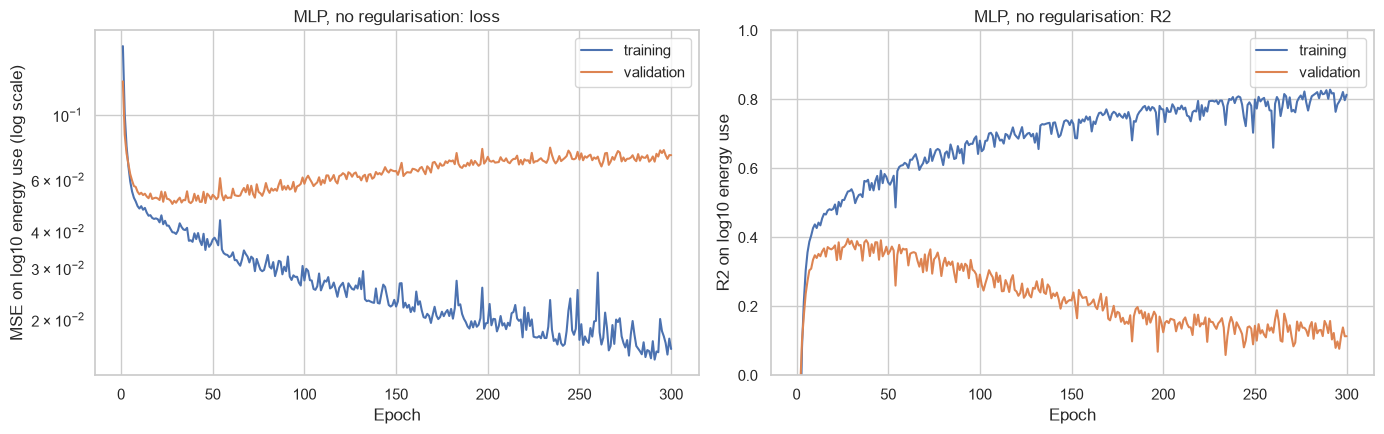

Lowest validation loss at epoch 28: R2 0.396


,train_loss,val_loss,train_r2,val_r2
epoch,,,,
1,0.172,0.130,-1.017,-0.584
10,0.048,0.054,0.438,0.348
50,0.038,0.053,0.559,0.351
100,0.027,0.058,0.680,0.292
300,0.016,0.073,0.814,0.113


In [9]:
def plot_history(history, title, paths=()):
    #loss and R2 per epoch, for the training and the validation part
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(history.index, history["train_loss"], label="training")
    axes[0].plot(history.index, history["val_loss"], label="validation")
    axes[0].set_yscale("log")
    axes[0].set_title(f"{title}: loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("MSE on log10 energy use (log scale)")
    axes[0].legend()
    axes[1].plot(history.index, history["train_r2"], label="training")
    axes[1].plot(history.index, history["val_r2"], label="validation")
    axes[1].set_ylim(0, 1)
    axes[1].set_title(f"{title}: R2")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("R2 on log10 energy use")
    axes[1].legend()
    plt.tight_layout()
    for path in paths:
        plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


plot_history(history, "MLP, no regularisation", [FIG_DIR / "01_training_curves.png"])

best_epoch = history["val_loss"].idxmin()
print(f"Lowest validation loss at epoch {best_epoch}: R2 {history.loc[best_epoch, 'val_r2']:.3f}")
history.iloc[[0, 9, 49, 99, -1]]

Both losses drop fast in the first 10 epochs. After that they split: the training loss keeps going down, while the validation loss is lowest at epoch 28 (validation R2 0.40) and then slowly goes up. At epoch 300 the network explains 81% of the variance of the training buildings but only 11% of the validation ones: it has memorised the training buildings. So it's still learning, but the wrong things, and we should stop around epoch 30. That's what we test in section 5.

# 4. Look inside
We use the inspection tools of the class notebook 01: the parameter table, the drawing of the network before and after training, and one building going through the layers.

In [10]:
#inspection tools from the class notebook 01

def parameter_table(model):
    # One row per weight matrix and bias vector: its shape, how many numbers it holds and their spread
    rows = []
    for name, p in model.named_parameters():
        values = p.detach().cpu().numpy()
        rows.append({"parameter": name, "shape": tuple(values.shape), "count": values.size,
                     "mean": values.mean(), "std": values.std(), "min": values.min(), "max": values.max()})
    return pd.DataFrame(rows).set_index("parameter")


def layer_outputs(model, x):
    # Pass x through a Sequential model one layer at a time and keep what comes out of each layer
    outputs = []
    with torch.no_grad():
        for name, layer in model.named_children():
            x = layer(x)
            outputs.append((f"{name}: {layer.__class__.__name__}", x.cpu()))
    return outputs


def draw_network(model, input_names=None, output_names=None, max_neurons=12, weight_scale=None, title=None, ax=None):
    # Draw the Linear (dense) layers of a model: circles are neurons, lines are weights.
    # Blue = positive weight, red = negative; the thicker and darker the line, the larger the weight.
    # weight_scale = the weight drawn at full strength (default: the largest one in each layer).
    # Wide layers only show their first `max_neurons` neurons.
    layers = list(model) if isinstance(model, nn.Sequential) else [model]
    linears = [layer for layer in layers if isinstance(layer, nn.Linear)]

    # A label under each layer, e.g. "Linear 8→32 + ReLU"
    labels = []
    for layer in layers:
        if isinstance(layer, nn.Linear):
            labels.append(f"Linear {layer.in_features}→{layer.out_features}")
        elif not isinstance(layer, nn.Dropout) and labels:
            labels[-1] += f"\n+ {layer.__class__.__name__}"

    sizes = [linears[0].in_features] + [layer.out_features for layer in linears]
    shown = [min(n, max_neurons) for n in sizes]
    spacing = [min(2 / max(n - 1, 1), 0.6) for n in shown]           # small layers are spread out more
    ys = [(np.arange(n) - (n - 1) / 2) * -gap for n, gap in zip(shown, spacing)]   # vertical position of each neuron

    if ax is None:
        fig, ax = plt.subplots(figsize=(2.8 * len(sizes) + 1, 6))

    # Lines: one per weight
    for l, layer in enumerate(linears):
        W = layer.weight.detach().cpu().numpy()[:shown[l + 1], :shown[l]]   # (outputs, inputs)
        scale = weight_scale or np.abs(W).max()
        for j, y_out in enumerate(ys[l + 1]):
            for i, y_in in enumerate(ys[l]):
                strength = min(abs(W[j, i]) / scale, 1)
                ax.plot([l, l + 1], [y_in, y_out], color="tab:blue" if W[j, i] > 0 else "tab:red",
                        lw=0.3 + 3 * strength, alpha=0.15 + 0.75 * strength, zorder=1)
                if W.size <= 12:                                           # tiny network: write the value too
                    ax.text(l + 0.3, y_in + 0.3 * (y_out - y_in), f"{W[j, i]:+.2f}", fontsize=9,
                            ha="center", va="bottom", color="dimgrey")

    # Circles: one per neuron, and the labels
    circle_size = np.clip(2500 / max(shown), 60, 700)
    for l, (n, y) in enumerate(zip(sizes, ys)):
        ax.scatter(np.full(len(y), l), y, s=circle_size, color="lightgrey" if l == 0 else "white",
                   edgecolors="black", zorder=2)
        if n > len(y):
            ax.text(l, y.min() - 0.12, f"+ {n - len(y)} more", ha="center", va="top", fontsize=9)
        ax.text(l, -1.3, "Input" if l == 0 else labels[l - 1], ha="center", va="top", fontsize=10)
    for name, y in zip(input_names or [], ys[0]):
        ax.text(-0.15, y, name, ha="right", va="center", fontsize=9)
    for name, y in zip(output_names or [], ys[-1]):
        ax.text(len(sizes) - 0.85, y, name, ha="left", va="center", fontsize=9)

    n_params = sum(p.numel() for p in model.parameters())
    ax.set_title(title or f"{n_params:,} parameters")
    ax.set_xlim(-1, len(sizes) - 0.2)
    ax.set_ylim(-1.7, 1.2)
    ax.axis("off")
    return ax

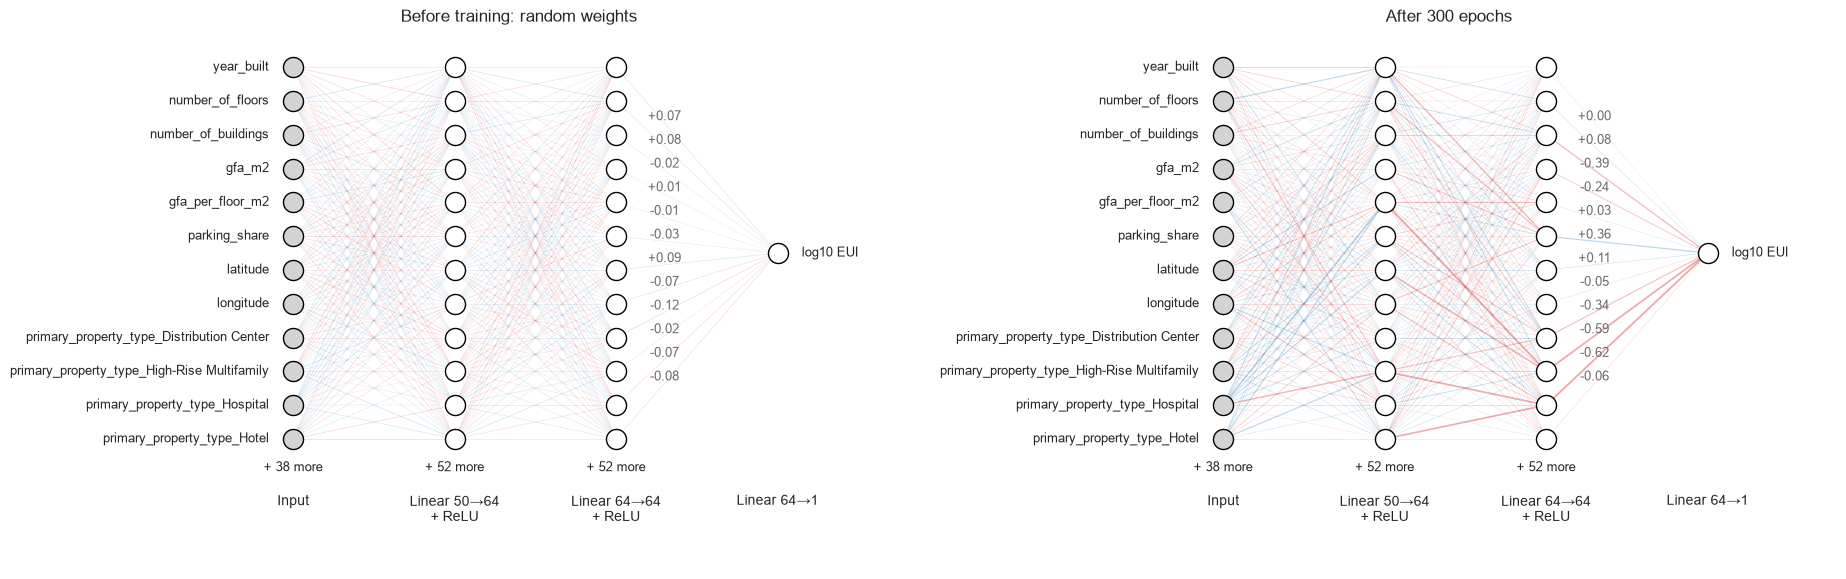

before              after             
             std    min   max   std    min   max
parameter                                       
0.weight   0.081 -0.141 0.141 0.202 -0.957 0.700
0.bias     0.087 -0.136 0.139 0.113 -0.241 0.257
3.weight   0.073 -0.125 0.125 0.169 -1.840 0.712
3.bias     0.072 -0.122 0.120 0.114 -0.320 0.247
6.weight   0.063 -0.117 0.123 0.240 -0.697 0.356
6.bias     0.000  0.065 0.065 0.000  0.223 0.223

In [11]:
#the network before and after training, drawn with the same line scale (first 12 inputs and neurons)
same_scale = max(layer.weight.abs().max().item() for layer in mlp if isinstance(layer, nn.Linear))

fig, axes = plt.subplots(1, 2, figsize=(22, 7))
draw_network(mlp_untrained, input_names, ["log10 EUI"], weight_scale=same_scale, ax=axes[0],
             title="Before training: random weights")
draw_network(mlp, input_names, ["log10 EUI"], weight_scale=same_scale, ax=axes[1],
             title=f"After {len(history)} epochs")
plt.savefig(FIG_DIR / "02_network_before_after.png", dpi=150, bbox_inches="tight")
plt.savefig(MODEL_DIR / "network_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

#the same in numbers: spread of the weights in each layer
pd.concat({"before": parameter_table(mlp_untrained)[["std", "min", "max"]],
           "after": parameter_table(mlp)[["std", "min", "max"]]}, axis=1)

Before training all the lines are thin: PyTorch starts with small random weights (between -0.14 and 0.14 in the first layer). After 300 epochs a few lines are much thicker and the spread of the weights has grown in every layer: the std of the first layer goes from 0.08 to 0.20, and the largest weight of the second layer reaches -1.84. Most weights stay small and a few become large.

The drawing only shows the first 12 of the 50 inputs and of the 64 neurons per layer. A thick line also doesn't mean an important input: each input is mixed through 64 + 64 neurons, and positive and negative paths can cancel out. To know which input matters we would use permutation importance, like on Day 2.

### One building through the network

primary_property_type     Low-Rise Multifamily
building_type             Multifamily LR (1-4)
neighborhood             MAGNOLIA / QUEEN ANNE
year_built                                1989
number_of_floors                         3.000
number_of_buildings                      1.000
gfa_m2                               3,238.046
gfa_per_floor_m2                     1,079.349
parking_share                            0.000
latitude                                47.659
longitude                             -122.400
Name: 2767, dtype: object
0: Linear  : shape (1, 64)
1: ReLU    : shape (1, 64)
2: Dropout : shape (1, 64)
3: Linear  : shape (1, 64)
4: ReLU    : shape (1, 64)
5: Dropout : shape (1, 64)
6: Linear  : shape (1, 1)
Active neurons: 37 of 64, then 26 of 64
Predicted 92, actual 87 kWh/m2 per year


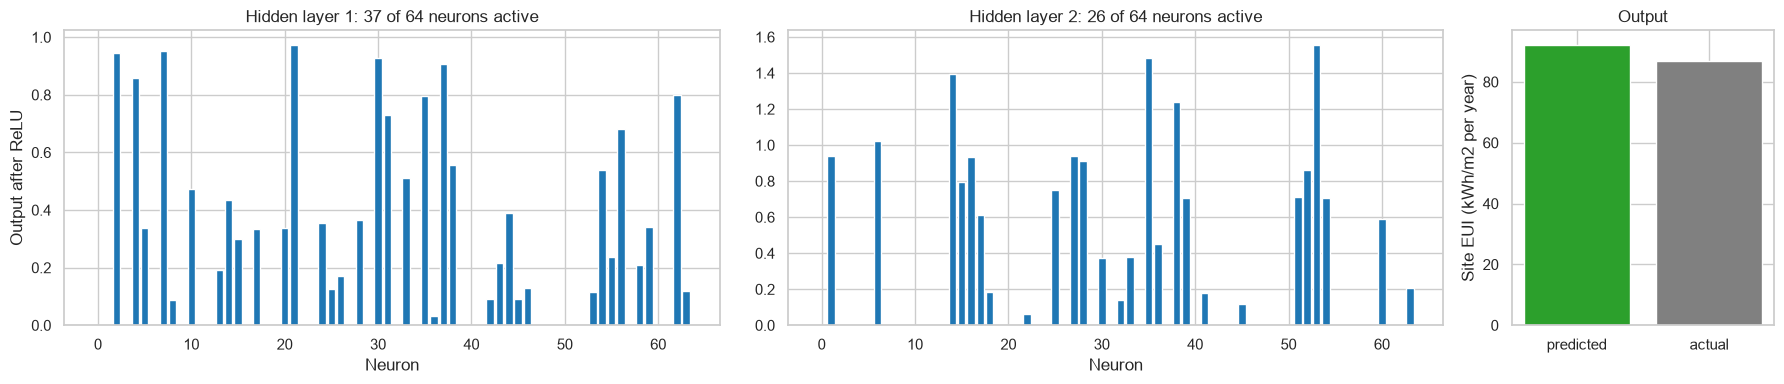

In [12]:
#one validation building through the network, layer by layer
example = 0
print(X_val.iloc[example])
steps = layer_outputs(mlp, X_val_t[example:example + 1])
for name, output in steps:
    print(f"{name:<11}: shape {tuple(output.shape)}")

hidden_1 = steps[1][1][0]   #after the first ReLU
hidden_2 = steps[4][1][0]   #after the second ReLU
predicted = 10 ** steps[6][1][0].item()
actual = 10 ** y_val.iloc[example]
print(f"Active neurons: {(hidden_1 > 0).sum()} of 64, then {(hidden_2 > 0).sum()} of 64")
print(f"Predicted {predicted:.0f}, actual {actual:.0f} kWh/m2 per year")

fig, axes = plt.subplots(1, 3, figsize=(18, 4), gridspec_kw={"width_ratios": [2, 2, 0.8]})
axes[0].bar(range(len(hidden_1)), hidden_1.numpy(), color="tab:blue")
axes[0].set_title(f"Hidden layer 1: {(hidden_1 > 0).sum()} of {len(hidden_1)} neurons active")
axes[0].set_xlabel("Neuron")
axes[0].set_ylabel("Output after ReLU")
axes[1].bar(range(len(hidden_2)), hidden_2.numpy(), color="tab:blue")
axes[1].set_title(f"Hidden layer 2: {(hidden_2 > 0).sum()} of {len(hidden_2)} neurons active")
axes[1].set_xlabel("Neuron")
axes[2].bar(["predicted", "actual"], [predicted, actual], color=["tab:green", "grey"])
axes[2].set_title("Output")
axes[2].set_ylabel("Site EUI (kWh/m2 per year)")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_one_building.png", dpi=150, bbox_inches="tight")
plt.show()

The first validation building is a low-rise apartment building from 1989 in Magnolia / Queen Anne. Its 50 inputs switch on 37 of the 64 neurons of the first layer and 26 of the second (ReLU sets the others to 0), and the output is 92 kWh/m2 against 87 in reality. Every building switches on a different mix of neurons: that's how the same weights give different answers.

# 5. Experiment: regularisation
We change one thing at a time and compare on the validation set. Every variant starts from the same seed.
- **early stopping**: stop when the validation loss hasn't improved for 30 epochs, and go back to the best weights;
- **dropout 0.3 with weight decay 0.001**, plus early stopping;
- a **smaller network**, 16 neurons per layer instead of 64, plus early stopping.

In [13]:
#same network, one change at a time, compared on the validation set
variants = {"no regularisation, 300 epochs": (mlp, history)}

torch.manual_seed(RANDOM_STATE)
model = make_mlp()
variants["early stopping"] = (model, train(model, epochs=300, patience=30))

torch.manual_seed(RANDOM_STATE)
model = make_mlp(dropout=0.3)
variants["dropout 0.3 + weight decay + early stopping"] = (model, train(model, epochs=300, weight_decay=1e-3, patience=30))

torch.manual_seed(RANDOM_STATE)
model = make_mlp(hidden=16)
variants["16 neurons + early stopping"] = (model, train(model, epochs=300, patience=30))

rows = {}
for name, (model, hist) in variants.items():
    val_pred = predict(model, X_val_t)
    rows[name] = {"epochs run": len(hist),
                  "validation R2": r2_score(y_val, val_pred),
                  "validation MAE (log10)": mean_absolute_error(y_val, val_pred)}
experiment_df = pd.DataFrame(rows).T
experiment_df["epochs run"] = experiment_df["epochs run"].astype(int)
experiment_df

,epochs run,validation R2,validation MAE (log10)
"no regularisation, 300 epochs",300,0.113,0.193
early stopping,58,0.396,0.161
dropout 0.3 + weight decay + early stopping,119,0.387,0.159
16 neurons + early stopping,106,0.385,0.161


Without regularisation the network ends at a validation R2 of 0.11. All three remedies bring it back to about 0.39: early stopping 0.396 (it stopped after 58 epochs and went back to epoch 28), dropout with weight decay 0.387, the small network 0.385. The three are within 0.011 of each other on 514 validation buildings, so we don't read much into the ranking: what matters is stopping in time. We keep the best one on validation, early stopping.

Best on validation: early stopping


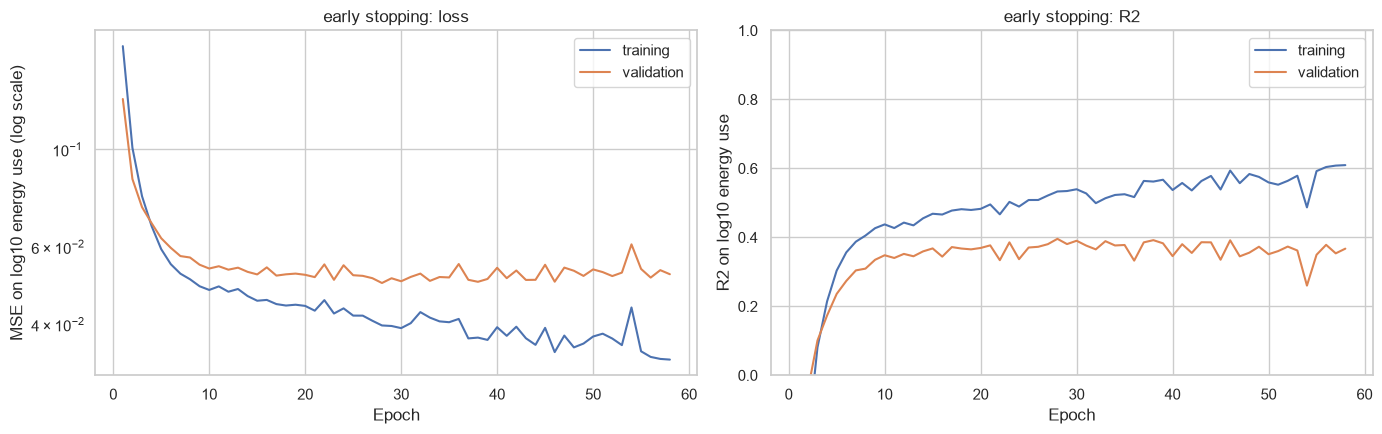

In [14]:
#the best variant on validation becomes our final network
best_name = experiment_df["validation R2"].idxmax()
best_mlp, best_history = variants[best_name]
print("Best on validation:", best_name)

plot_history(best_history, best_name, [FIG_DIR / "04_training_curves_final.png", MODEL_DIR / "training_curves.png"])

The final network is the same as the first one, stopped at epoch 28, where the validation loss was lowest.

# 6. Test set, once

In [15]:
#the three models on the same 643 test buildings: the only time we use the test set
y_pred_mean = mean_model.predict(X_test)
y_pred_rf = day2_model.predict(X_test)
y_pred_mlp = predict(best_mlp, X_test_t)

test_df = pd.DataFrame({"Mean (baseline)": scores(y_test, y_pred_mean),
                        "Random forest (Day 2)": scores(y_test, y_pred_rf),
                        "MLP (this notebook)": scores(y_test, y_pred_mlp)}).T
test_df

,R2 (log10),MAE (kWh/m2),typical error (%),underestimated (%)
Mean (baseline),-0.000,88.914,65.925,49.145
Random forest (Day 2),0.387,68.162,45.079,48.678
MLP (this notebook),0.382,69.365,45.540,46.345


On the 643 test buildings the network and the Day 2 random forest are practically tied: R2 0.382 against 0.387, MAE 69 against 68 kWh/m2, a typical error of about 46% against 45%. Both are far better than the mean (MAE 89 kWh/m2). The network underestimates a bit less often (46% of the buildings against 49%), which is the costly mistake in our use case, but the gap is small.

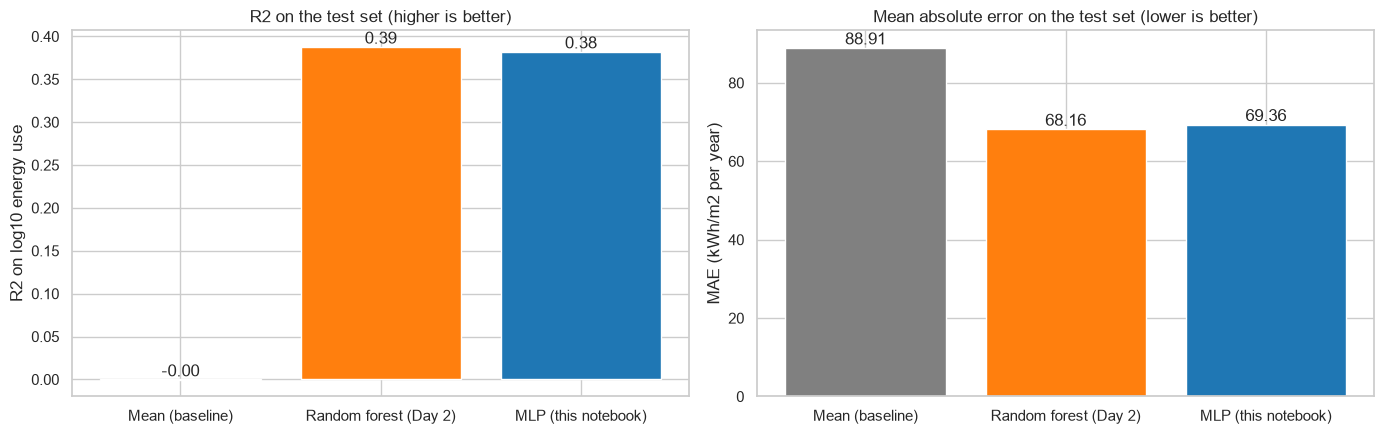

In [16]:
#network vs Day 2 model vs baseline
colors = ["grey", "tab:orange", "tab:blue"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(test_df.index, test_df["R2 (log10)"], color=colors)
axes[0].set_title("R2 on the test set (higher is better)")
axes[0].set_ylabel("R2 on log10 energy use")
axes[1].bar(test_df.index, test_df["MAE (kWh/m2)"], color=colors)
axes[1].set_title("Mean absolute error on the test set (lower is better)")
axes[1].set_ylabel("MAE (kWh/m2 per year)")
for ax, column in zip(axes, ["R2 (log10)", "MAE (kWh/m2)"]):
    for i, value in enumerate(test_df[column]):
        ax.text(i, value, f"{value:.2f}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_test_comparison.png", dpi=150, bbox_inches="tight")
plt.savefig(MODEL_DIR / "test_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

The bars show the same thing: the network doesn't beat the random forest.

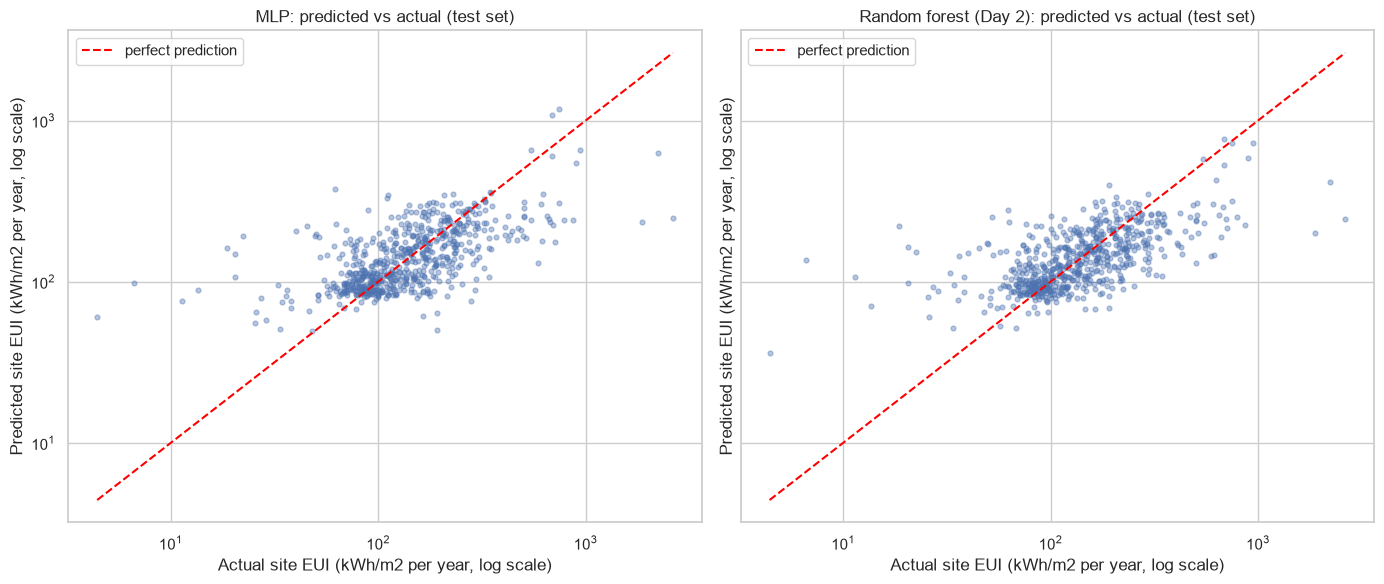

Correlation between the two models' predictions: 0.90


In [17]:
#predicted vs actual, network and random forest side by side
y_test_kwh = 10 ** y_test
limits = [y_test_kwh.min(), y_test_kwh.max()]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, y_pred, title in zip(axes, [y_pred_mlp, y_pred_rf], ["MLP", "Random forest (Day 2)"]):
    ax.scatter(y_test_kwh, 10 ** y_pred, alpha=0.4, s=12)
    ax.plot(limits, limits, color="red", linestyle="--", label="perfect prediction")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{title}: predicted vs actual (test set)")
    ax.set_xlabel("Actual site EUI (kWh/m2 per year, log scale)")
    ax.set_ylabel("Predicted site EUI (kWh/m2 per year, log scale)")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "06_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.savefig(MODEL_DIR / "predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

#how far apart are the two models on the same buildings?
print(f"Correlation between the two models' predictions: {np.corrcoef(y_pred_mlp, y_pred_rf)[0, 1]:.2f}")

The two clouds look almost the same, and the two models' predictions are correlated at 0.90. Both pull the predictions towards the middle: the buildings that use very little are overestimated, and the few that use more than 1,000 kWh/m2 are strongly underestimated by both. The network also has a few points far above the line, like the two buildings it predicts above 1,000 kWh/m2.

### Where does each model fail?

In [18]:
#median % error per use, for the uses with at least 10 test buildings
use_df = pd.DataFrame({"use": X_test["primary_property_type"],
                       "MLP error (%)": (10 ** y_pred_mlp - y_test_kwh).abs() / y_test_kwh * 100,
                       "random forest error (%)": (10 ** y_pred_rf - y_test_kwh).abs() / y_test_kwh * 100})
use_counts = use_df["use"].value_counts()
common_uses = use_counts[use_counts >= 10].index
use_table = use_df[use_df["use"].isin(common_uses)].groupby("use").median()
use_table["test buildings"] = use_counts[common_uses]
use_table.sort_values("MLP error (%)", ascending=False)

,MLP error (%),random forest error (%),test buildings
use,,,
Other,51.896,51.516,52
Warehouse,51.887,48.762,37
Mixed Use Property,50.463,38.927,38
Worship Facility,41.508,31.626,10
K-12 School,37.974,28.613,12
Small- and Mid-Sized Office,28.717,25.709,61
High-Rise Multifamily,28.641,16.413,19
Retail Store,27.092,31.357,22
Large Office,26.005,35.872,37


By use, the two models make different mistakes. The network is clearly worse on high-rise apartments (median error 29% against 16%), mixed use buildings (50% against 39%) and schools (38% against 29%), and better on large offices (26% against 36%), hotels (17% against 26%) and medical offices (14% against 20%). Warehouses and the "Other" group stay around 50% for both: the use alone doesn't say what happens inside. With 10 to 181 test buildings per use these medians are rough.

# 7. Application: design options
Three options an architect could compare in a feasibility study, all new (2016): a 6 floor apartment block in the East, an 8 floor office downtown and a one storey warehouse in Greater Duwamish. We give them to the network and to the Day 2 random forest.

In [19]:
#three design options an architect could test in a feasibility study
design_options = pd.DataFrame({
    "primary_property_type": ["Mid-Rise Multifamily", "Small- and Mid-Sized Office", "Warehouse"],
    "building_type": ["Multifamily MR (5-9)", "Nonresidential", "Nonresidential"],
    "neighborhood": ["EAST", "DOWNTOWN", "GREATER DUWAMISH"],
    "year_built": [2016, 2016, 2016],
    "number_of_floors": [6, 8, 1],
    "number_of_buildings": [1, 1, 1],
    "gfa_m2": [6000, 12000, 5000],
    "gfa_per_floor_m2": [1000, 1500, 5000],
    "parking_share": [0.1, 0.2, 0.0],
    "latitude": [47.615, 47.608, 47.555],
    "longitude": [-122.315, -122.335, -122.335],
}, index=["apartment block, 6 floors", "office, 8 floors", "warehouse, 1 floor"])

X_options_t = torch.tensor(preprocessing.transform(design_options), dtype=torch.float32)
predictions = pd.DataFrame({"MLP (kWh/m2)": 10 ** predict(best_mlp, X_options_t),
                            "random forest (kWh/m2)": 10 ** day2_model.predict(design_options)},
                           index=design_options.index)
predictions

,MLP (kWh/m2),random forest (kWh/m2)
"apartment block, 6 floors",117.493,88.548
"office, 8 floors",222.837,161.931
"warehouse, 1 floor",89.651,116.475


Both models put the office highest, but the numbers differ a lot: the network gives 33% more for the apartment block (117 against 89 kWh/m2) and 38% more for the office (223 against 162), and 23% less for the warehouse (90 against 116). With a typical error around 45%, both only give an order of magnitude for a feasibility study, and the gap between the two models is a good reminder of that.

# 8. Save, reload and use
We save the weights with `torch.save(model.state_dict())` and the fitted preprocessing with `joblib`. We call it `scaler.joblib` like the brief, but it holds the whole `ColumnTransformer`: the imputers, the scaler and the one-hot encoder. A user needs both files, plus the code of `make_mlp` to rebuild the architecture. Then we reload them in new objects, as a user would, and check that the predictions are the same.

In [20]:
#the two files a user needs: the weights and the fitted preprocessing
torch.save(best_mlp.state_dict(), MODEL_DIR / "model.pt")
joblib.dump(preprocessing, MODEL_DIR / "scaler.joblib")

#reload as a user would: rebuild the architecture, load the weights and the preprocessing
reloaded = make_mlp(hidden=best_mlp[0].out_features)
reloaded.load_state_dict(torch.load(MODEL_DIR / "model.pt"))
reloaded_preprocessing = joblib.load(MODEL_DIR / "scaler.joblib")

#check it gives the same test predictions as before
X_check = torch.tensor(reloaded_preprocessing.transform(X_test), dtype=torch.float32)
assert np.allclose(predict(reloaded, X_check), y_pred_mlp)

#one new building: the apartment block from section 7
x_new = torch.tensor(reloaded_preprocessing.transform(design_options.iloc[[0]]), dtype=torch.float32)
print(f"Predicted energy use: {10 ** predict(reloaded, x_new)[0]:.0f} kWh/m2 per year")

Predicted energy use: 117 kWh/m2 per year


The reloaded network gives exactly the same test predictions, and 117 kWh/m2 for the apartment block of section 7.

# 9. Conclusions

### What we found
- On the same 643 test buildings the network ties with our Day 2 random forest: R2 0.382 against 0.387, MAE 69 against 68 kWh/m2, both around 45% typical error. Both beat the mean (MAE 89).
- Without regularisation the network memorises the training buildings: after 300 epochs R2 0.81 on training and 0.11 on validation. Stopping at the best validation epoch (28) fixes it, and dropout with weight decay or a smaller network give almost the same.
- The two models fail on different buildings: the network is worse on high-rise apartments, mixed use and schools, and better on large offices, hotels and medical offices.
- On 2,000 rows and 11 columns a network isn't worth it here: same accuracy, harder to explain, and the preprocessing has to be saved and loaded separately. What limits both models is the data: the hours, the equipment and the people in the building aren't in the table.

### Limitations and biases
- The network learned on 2,054 buildings and the random forest on all 2,568 (it didn't need a validation set), so the comparison slightly favours the random forest.
- One seed and one validation split. With 514 validation buildings, the ranking of the three experiments (0.385 to 0.396) is within noise.
- The same data limits as Day 2: only large buildings that report, only Seattle, only 2016, self-reported data. It's not meant for data centers, labs or very mixed buildings.
- It's a first estimate for a feasibility study, not a number for design decisions or for judging a specific building.